In [1]:
import numpy as np
import pandas as pd

# Load the arrays of features
A_ = pd.read_csv('A_2.csv').to_numpy()
B_ = pd.read_csv('B_2.csv').to_numpy()
C_ = pd.read_csv('C_2.csv').to_numpy()
D_ = pd.read_csv('D_2.csv').to_numpy()


# Check shapes
print("A_array:", A_.shape)
print("B_array:", B_.shape)
print("C_array:", C_.shape)
print("D_array:", D_.shape)


A_array: (41, 23)
B_array: (635, 23)
C_array: (5954, 23)
D_array: (993, 23)


In [2]:
# On position  0, 4, 19, 20 are BM, S_B, R and R'.

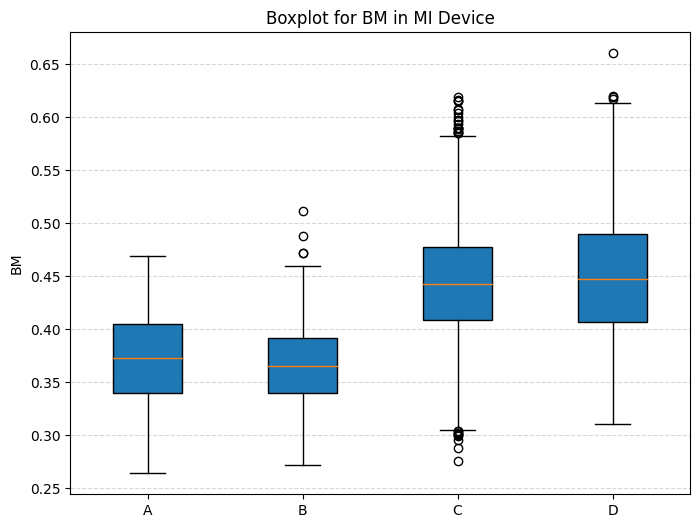

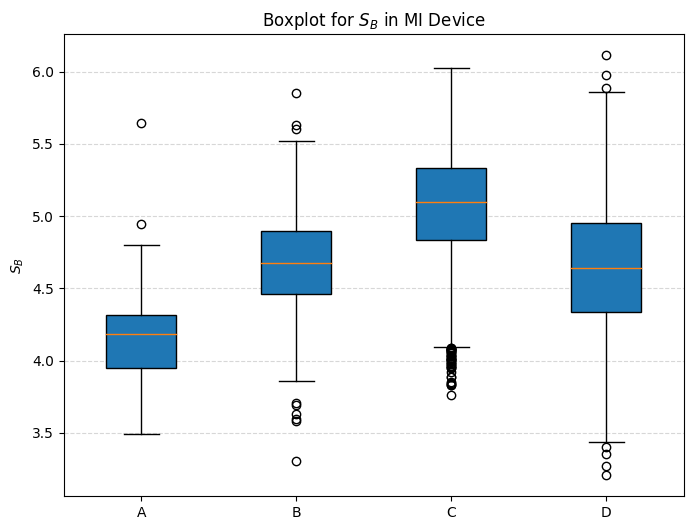

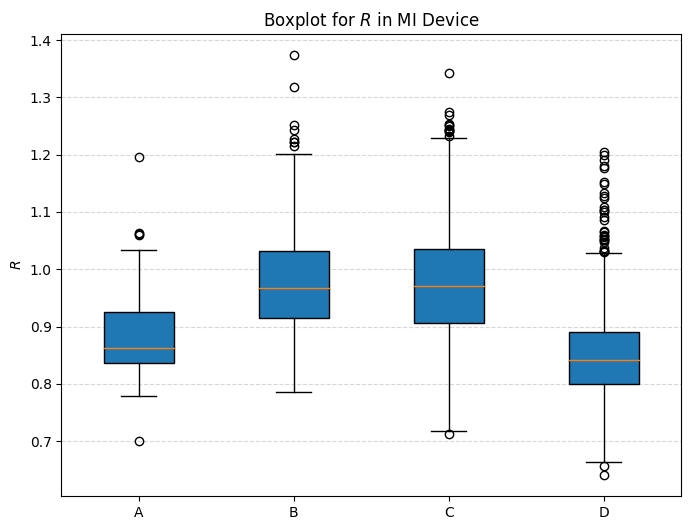

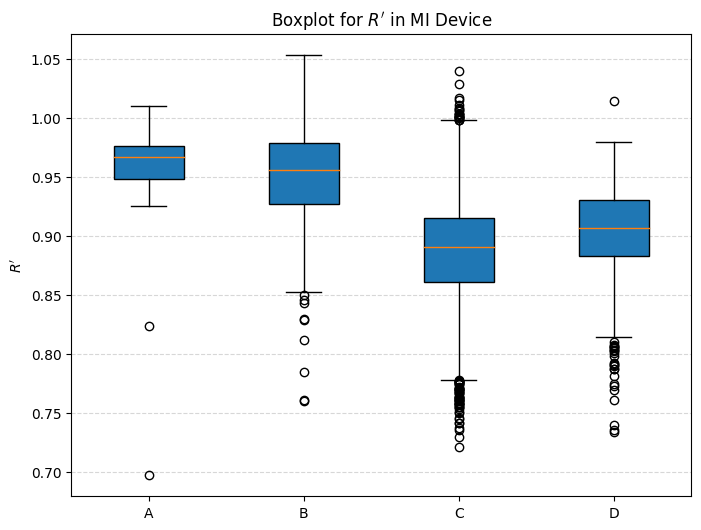

In [2]:
import matplotlib.pyplot as plt

feature_names = [
    "BM", "DOL1", "DOL2", "$S_D$", "$S_B$", "$S'_D$", "$S'_B$", "e__1", "e__2", "e__3", "e__4",
    "r_21", "r__43", "bm2", "DOL1", "DOL2", "e11", "e22", "E", "$R$", "$R'$", "e22/e11", "Age"
]

# Selected feature indices
selected_indices = [0, 4, 19, 20]

assert A_.shape[1] >= len(feature_names), "Not enough columns in A, B, C, or D arrays."

# Plot only selected features
for i in selected_indices:
    name = feature_names[i]
    plt.figure(figsize=(8, 6))
    plt.boxplot([A_[:, i], B_[:, i], C_[:, i], D_[:, i]], 
                labels=['A', 'B', 'C', 'D'], 
                patch_artist=True)
    
    plt.title(f"Boxplot for {name} in MI Device")
    plt.ylabel(name)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()


# 1
### ANOVA (one-way) tests for each pairs in Bm coeficient

In [3]:
from scipy.stats import f_oneway

pairs = [
    ('A-B', A_[:,0], B_[:,0]),
    ('A-C', A_[:,0], C_[:,0]),
    ('A-D', A_[:,0], D_[:,0]),
    ('B-C', B_[:,0], C_[:,0]),
    ('B-D', B_[:,0], D_[:,0]),
    ('C-D', C_[:,0], D_[:,0])
]

# Perform ANOVA for each pair
for name, x, y in pairs:
    f_stat, p_val = f_oneway(x, y)
    print(f'ANOVA {name}: F-statistic = {f_stat:.4f}, p-value = {p_val:.4e}')


ANOVA A-B: F-statistic = 0.7169, p-value = 3.9747e-01
ANOVA A-C: F-statistic = 80.2733, p-value = 4.2840e-19
ANOVA A-D: F-statistic = 71.8920, p-value = 7.7782e-17
ANOVA B-C: F-statistic = 1360.9319, p-value = 5.4487e-271
ANOVA B-D: F-statistic = 1028.5700, p-value = 2.7258e-175
ANOVA C-D: F-statistic = 12.9793, p-value = 3.1715e-04


#### Analzsis for Bm -> Threshold = 75th percentile on first (min) class

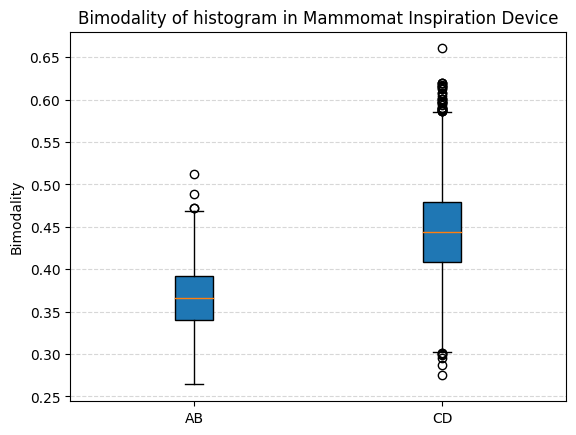

<Figure size 600x500 with 0 Axes>

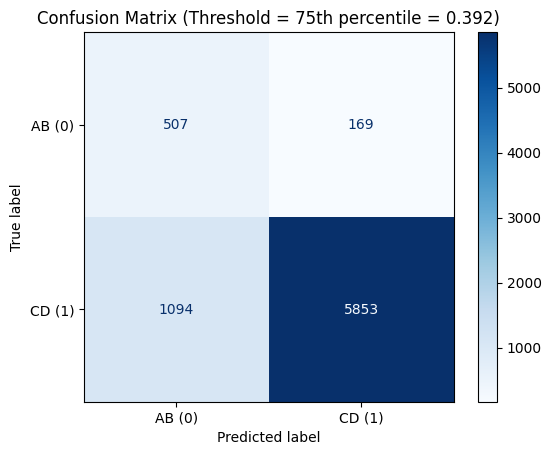

Threshold (75th percentile of AB): 0.392
Confusion Matrix:
 [[ 507  169]
 [1094 5853]]
Accuracy : 0.8343
Precision: 0.9719
Recall   : 0.8425
F1-score : 0.9026


In [4]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score
)


AB = np.concatenate((A_[:,0], B_[:,0]), axis = 0)
CD = np.concatenate((C_[:,0], D_[:,0]), axis = 0)


plt.boxplot([AB, CD], labels=['AB', 'CD'], patch_artist=True)

plt.title("Bimodality of histogram in Mammomat Inspiration Device")
plt.ylabel("Bimodality")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


###################3
# Compute threshold (75th percentile of AB)
threshold = np.percentile(AB, 75)

# True labels (AB = 0, CD = 1)
y_true = np.concatenate((
    np.zeros(len(AB)),
    np.ones(len(CD))
))

# Predictions (based on threshold)
y_pred = np.concatenate((
    (AB >= threshold).astype(int),
    (CD >= threshold).astype(int)
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['AB (0)', 'CD (1)'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Threshold = 75th percentile = {threshold:.3f})")
plt.show()

# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

# Print results
print(f"Threshold (75th percentile of AB): {threshold:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")



# 2
### ANOVA (one-way) tests for each pairs in $R'$  coeficient


In [5]:
pairs = [
    ('A-B', A_[:,20], B_[:,20]),
    ('A-C', A_[:,20], C_[:,20]),
    ('A-D', A_[:,20], D_[:,20]),
    ('B-C', B_[:,20], C_[:,20]),
    ('B-D', B_[:,20], D_[:,20]),
    ('C-D', C_[:,20], D_[:,20])
]

for name, x, y in pairs:
    f_stat, p_val = f_oneway(x, y)
    print(f'ANOVA {name}: F-statistic = {f_stat:.4f}, p-value = {p_val:.4e}')

ANOVA A-B: F-statistic = 0.4980, p-value = 4.8062e-01
ANOVA A-C: F-statistic = 101.1779, p-value = 1.2933e-23
ANOVA A-D: F-statistic = 66.7774, p-value = 8.8345e-16
ANOVA B-C: F-statistic = 1265.4233, p-value = 1.1009e-253
ANOVA B-D: F-statistic = 562.6119, p-value = 4.7241e-107
ANOVA C-D: F-statistic = 121.1128, p-value = 6.1368e-28


#### Analzsis for $R'$ -> Threshold = 75th percentile on first (min) class

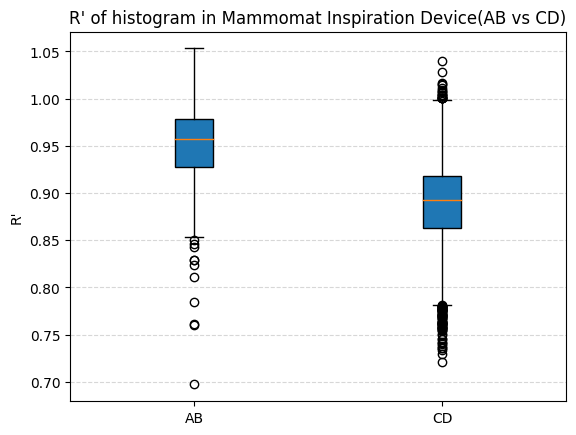

<Figure size 600x500 with 0 Axes>

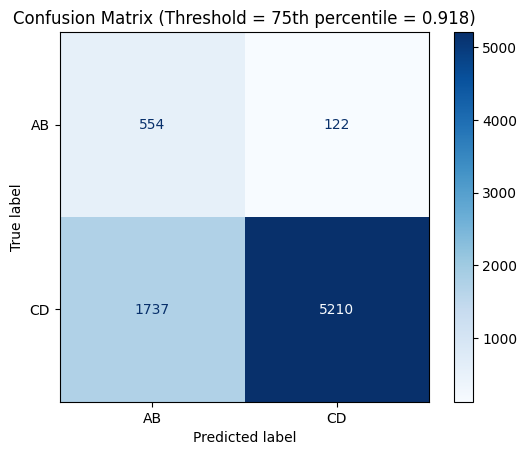

Threshold (75th percentile of CD): 0.918
Confusion Matrix:
 [[ 554  122]
 [1737 5210]]
Accuracy : 0.7561
Precision: 0.9771
Recall   : 0.7500
F1-score : 0.8486


In [6]:
AB = np.concatenate((A_[:,20], B_[:,20]), axis = 0)
CD = np.concatenate((C_[:,20], D_[:,20]), axis = 0)

plt.boxplot([AB, CD], labels=['AB', 'CD'], patch_artist=True)

plt.title("R' of histogram in Mammomat Inspiration Device(AB vs CD)")
plt.ylabel("R'")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



threshold = np.percentile(CD, 75)

y_true = np.concatenate((
    np.zeros(len(AB)),
    np.ones(len(CD))
))

y_pred = np.concatenate((
    (AB <= threshold).astype(int),
    (CD <= threshold).astype(int)
))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['AB', 'CD'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Threshold = 75th percentile = {threshold:.3f})")
plt.show()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Threshold (75th percentile of CD): {threshold:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

###########################################################3

# 3
### ANOVA (one-way) tests for each pairs in $S_B$ coeficient

In [7]:
pairs = [
    ('A-B', A_[:,4], B_[:,4]),
    ('A-C', A_[:,4], C_[:,4]),
    ('A-D', A_[:,4], D_[:,4]),
    ('B-C', B_[:,4], C_[:,4]),
    ('B-D', B_[:,4], D_[:,4]),
    ('C-D', C_[:,4], D_[:,4])
]

# ANOVA 
for name, x, y in pairs:
    f_stat, p_val = f_oneway(x, y)
    print(f'ANOVA {name}: F-statistic = {f_stat:.4f}, p-value = {p_val:.4e}')

ANOVA A-B: F-statistic = 75.0556, p-value = 3.3774e-17
ANOVA A-C: F-statistic = 240.7412, p-value = 2.9129e-53
ANOVA A-D: F-statistic = 36.2982, p-value = 2.3527e-09
ANOVA B-C: F-statistic = 687.2398, p-value = 3.5860e-144
ANOVA B-D: F-statistic = 3.8447, p-value = 5.0073e-02
ANOVA C-D: F-statistic = 1131.9788, p-value = 4.9243e-230


#### Analzsis for $S_B$ -> Threshold = 75th percentile on first (min) class

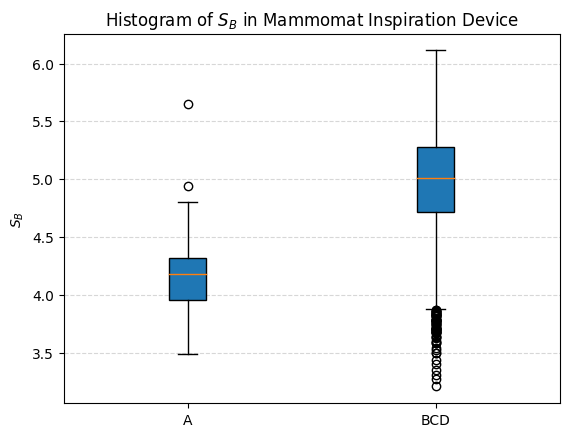

<Figure size 600x500 with 0 Axes>

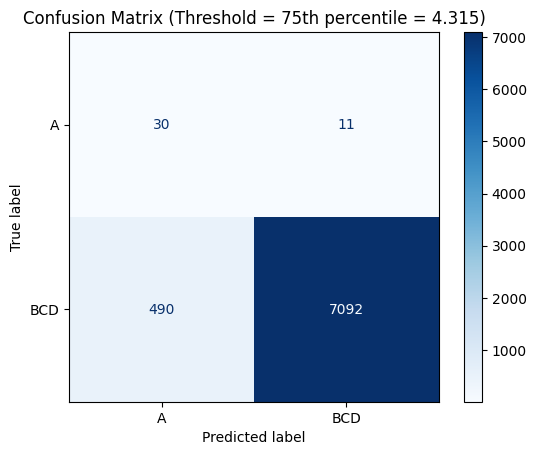

Threshold (75th percentile of A): 4.315
Confusion Matrix:
 [[  30   11]
 [ 490 7092]]
Accuracy : 0.9343
Precision: 0.9985
Recall   : 0.9354
F1-score : 0.9659


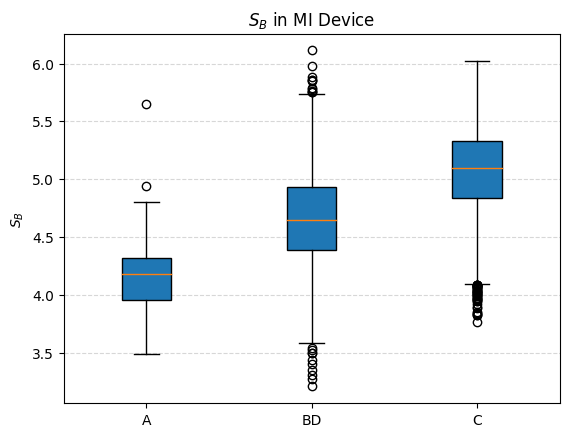

<Figure size 600x500 with 0 Axes>

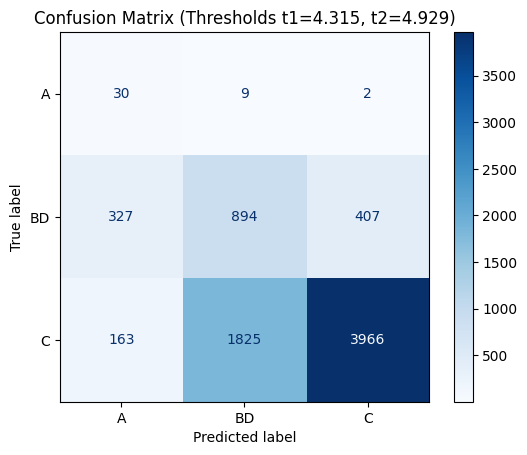

Thresholds: t1(A)=4.315, t2(BD)=4.929
Confusion Matrix:
 [[  30    9    2]
 [ 327  894  407]
 [ 163 1825 3966]]
Accuracy : 0.6415
Precision: 0.4306
Recall   : 0.6490
F1-score : 0.4285


In [8]:

A = A_[:,4]
BCD = np.concatenate((B_[:,4], C_[:,4], D_[:,4]), axis = 0)


plt.boxplot([A, BCD], labels=['A', 'BCD'], patch_artist=True)

plt.title("Histogram of $S_B$ in Mammomat Inspiration Device")
plt.ylabel("$S_B$")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


threshold = np.percentile(A, 75)

y_true = np.concatenate((
    np.zeros(len(A)),
    np.ones(len(BCD))
))

y_pred = np.concatenate((
    (A >= threshold).astype(int),
    (BCD >= threshold).astype(int)
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['A', 'BCD'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Threshold = 75th percentile = {threshold:.3f})")
plt.show()

# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Threshold (75th percentile of A): {threshold:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
#############################################################
from sklearn.metrics import ConfusionMatrixDisplay

A = A_[:,4]
BD = np.concatenate((B_[:,4], D_[:,4]), axis = 0)
C = C_[:,4]

plt.boxplot([A, BD, C], labels=['A', 'BD', 'C'], patch_artist=True)
plt.title("$S_B$ in MI Device")
plt.ylabel("$S_B$")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# thresholds (75th percentiles for hg class)
t1 = np.percentile(A, 75)
t2 = np.percentile(BD, 75)


all_values = np.concatenate([A, BD, C])
y_true = np.concatenate([
    np.full(len(A), 0),  # A = 0
    np.full(len(BD), 1),  # BD = 1
    np.full(len(C), 2),  # C = 2
])

y_pred = []
for val in all_values:
    if val < t1:
        y_pred.append(0)  # A
    elif val < t2:
        y_pred.append(1)  # BD
    else:
        y_pred.append(2)  # C

y_pred = np.array(y_pred)

labels = ['A', 'BD', 'C']
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Thresholds t1={t1:.3f}, t2={t2:.3f})")
plt.show()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
f1 = f1_score(y_true, y_pred, average='macro')

print(f"Thresholds: t1(A)={t1:.3f}, t2(BD)={t2:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


# 4 
### ANOVA (one-way) tests for each pairs in $R$  coeficient

In [9]:
pairs = [
    ('A-B', A_[:,19], B_[:,19]),
    ('A-C', A_[:,19], C_[:,19]),
    ('A-D', A_[:,19], D_[:,19]),
    ('B-C', B_[:,19], C_[:,19]),
    ('B-D', B_[:,19], D_[:,19]),
    ('C-D', C_[:,19], D_[:,19])
]

for name, x, y in pairs:
    f_stat, p_val = f_oneway(x, y)
    print(f'ANOVA {name}: F-statistic = {f_stat:.4f}, p-value = {p_val:.4e}')

ANOVA A-B: F-statistic = 36.4503, p-value = 2.5866e-09
ANOVA A-C: F-statistic = 34.1855, p-value = 5.2741e-09
ANOVA A-D: F-statistic = 9.3859, p-value = 2.2433e-03
ANOVA B-C: F-statistic = 0.7450, p-value = 3.8808e-01
ANOVA B-D: F-statistic = 881.1856, p-value = 4.2195e-155
ANOVA C-D: F-statistic = 1601.5058, p-value = 2.6029e-315


#### Analzsis for R -> Threshold = 75th percentile on first (min) (class for *A vs B and *C vs D)

Report for A vs B


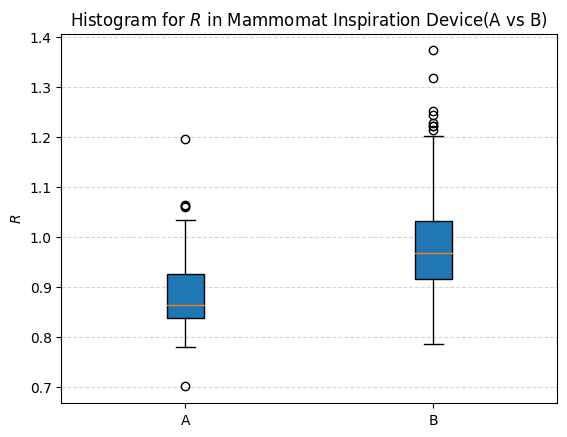

<Figure size 600x500 with 0 Axes>

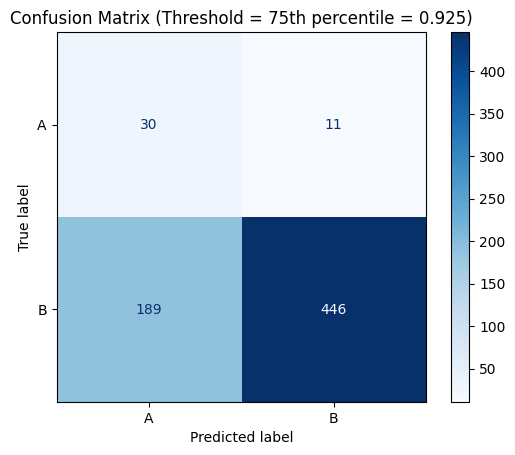

Threshold (75th percentile of A): 0.925
Confusion Matrix:
 [[ 30  11]
 [189 446]]
Accuracy : 0.7041
Precision: 0.9759
Recall   : 0.7024
F1-score : 0.8168
Report for C vs D


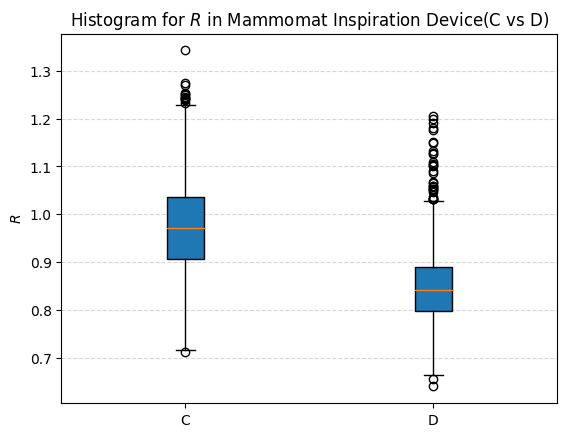

<Figure size 600x500 with 0 Axes>

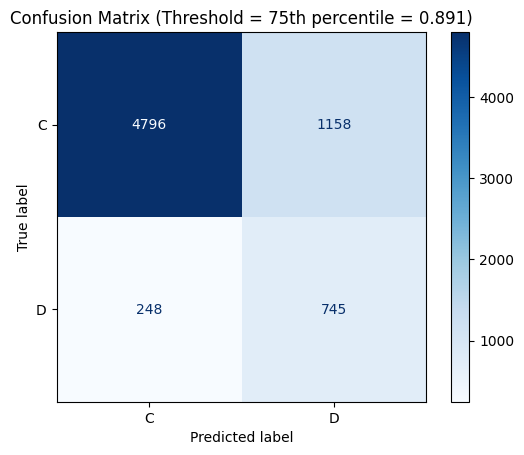

Threshold (75th percentile of D): 0.891
Confusion Matrix:
 [[4796 1158]
 [ 248  745]]
Accuracy : 0.7976
Precision: 0.3915
Recall   : 0.7503
F1-score : 0.5145
Report for AD vs CB


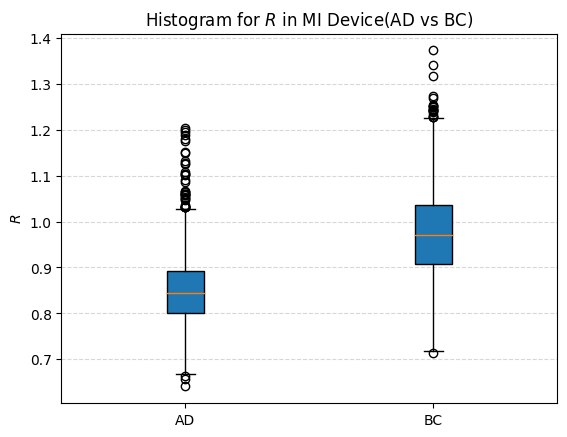

<Figure size 600x500 with 0 Axes>

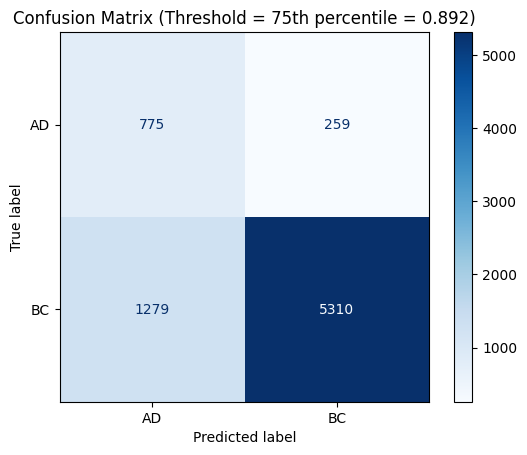

Threshold (75th percentile of AD): 0.892
Confusion Matrix:
 [[ 775  259]
 [1279 5310]]
Accuracy : 0.7982
Precision: 0.9535
Recall   : 0.8059
F1-score : 0.8735


In [10]:
print("Report for A vs B")

A = A_[:,19]
B = B_[:,19]


plt.boxplot([A, B], labels=['A', 'B'], patch_artist=True)

plt.title("Histogram for $R$ in Mammomat Inspiration Device(A vs B)")
plt.ylabel("$R$")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



threshold = np.percentile(A, 75)

y_true = np.concatenate((
    np.zeros(len(A)),
    np.ones(len(B))
))

y_pred = np.concatenate((
    (A >= threshold).astype(int),
    (B >= threshold).astype(int)
))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['A', 'B'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Threshold = 75th percentile = {threshold:.3f})")
plt.show()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Threshold (75th percentile of A): {threshold:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

###########################################################3

print("Report for C vs D")

C = C_[:,19]
D = D_[:,19]


plt.boxplot([C, D], labels=['C', 'D'], patch_artist=True)

plt.title("Histogram for $R$ in Mammomat Inspiration Device(C vs D)")
plt.ylabel("$R$")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



threshold = np.percentile(D, 75)

y_true = np.concatenate((
    np.zeros(len(C)),
    np.ones(len(D))
))

y_pred = np.concatenate((
    (C <= threshold).astype(int),
    (D <= threshold).astype(int)
))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['C', 'D'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Threshold = 75th percentile = {threshold:.3f})")
plt.show()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Threshold (75th percentile of D): {threshold:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


###########################################################3

print("Report for AD vs CB")
AD = np.concatenate((A_[:,19], D_[:,19]), axis = 0)
BC = np.concatenate((B_[:,19], C_[:,19]), axis = 0)

plt.boxplot([AD, BC], labels=['AD', 'BC'], patch_artist=True)

plt.title("Histogram for $R$ in MI Device(AD vs BC)")
plt.ylabel("$R$")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



threshold = np.percentile(AD, 75)

y_true = np.concatenate((
    np.zeros(len(AD)),
    np.ones(len(BC))
))

y_pred = np.concatenate((
    (AD >= threshold).astype(int),
    (BC >= threshold).astype(int)
))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['AD', 'BC'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Threshold = 75th percentile = {threshold:.3f})")
plt.show()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Threshold (75th percentile of AD): {threshold:.3f}")
print("Confusion Matrix:\n", cm)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

###########################################################3
